# RNN: sáu lớp học được, Scratch – Keras – PyTorch

    Notebook bổ sung cho báo cáo Chương 3–4. Mỗi nhóm cell trình bày
    **công thức → hàm → code → kết quả → giải thích**.
    Chọn Run All trong môi trường `.venv` của dự án. Notebook dùng dữ liệu
    VN-Index thật đã xử lý và chia theo thời gian, không tải mạng.
    Chỉ dùng 256 mẫu train, 128 validation và 256 test để demo trong thời gian ngắn;
    đây là thực nghiệm trên tập con, không thay thế benchmark toàn bộ dữ liệu.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 01: Thiết lập một phiên chạy thống nhất

Giới hạn biến môi trường luồng tính toán ở 2, chọn Keras backend TensorFlow, tìm ROOT có src/tieuluan và đổi thư mục chạy về ROOT. Import NumPy/Pandas/Matplotlib và tạo OUT=results/tieuluan/complete/notebooks. Điều kiện môi trường đặt trước khi nạp backend giúp giảm khác biệt số luồng.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `ROOT`, `OUT`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [1]:
# Cell RNN-01
import os, sys, json, time, inspect, copy
from pathlib import Path
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[key] = '2'
os.environ['KERAS_BACKEND'] = 'tensorflow'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'src/tieuluan').exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
OUT = ROOT/'results/tieuluan/complete/notebooks'
OUT.mkdir(parents=True, exist_ok=True)
print('Project:', ROOT)

Project: E:\WINDOW\Project\intelligent-system-assignment-01


## Dữ liệu và kiểu đầu vào–đầu ra

    Giữ đúng ranh giới thời gian của bộ dữ liệu đã chuẩn hóa từ train.
    Lấy 256 mẫu cuối của train, 128 mẫu đầu val và 256 mẫu đầu test.
    In ngày quan sát/ngày nhãn và phân bố lớp để người xem kiểm tra.
    `train_x`, `val_x`, `test_x` là tensor; nhãn có shape B × 1.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 02: Lấy mẫu VN-Index và kiểm ranh giới thời gian

KIND quyết định image [N,1,20,20] cho CNN hoặc sequence [N,20,1] cho recurrent. Đọc vnindex.npz, chọn 256 mẫu cuối train, 128 đầu validation và 256 đầu test, copy mảng và reshape nhãn [N,1]. assert ngày nhãn train trước val và nhãn val trước test; không tự kiểm mọi phép tiền xử lý đã tạo NPZ.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `KIND`, `representation`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. `assert` chỉ dừng khi điều kiện cụ thể trong mã sai; các ca đi qua không phải bằng chứng rằng mọi đầu vào đều đúng.


In [2]:
# Cell RNN-02
KIND = 'rnn'
representation = 'image' if KIND == 'cnn' else 'sequence'
with np.load(ROOT/'data/tieuluan/processed/vnindex.npz') as archive:
    data = {}
    ranges = {'train':slice(-256,None), 'val':slice(0,128),
              'test':slice(0,256)}
    inventory = []
    for split, selection in ranges.items():
        data[split+'_x'] = archive[split+'_'+representation][selection].copy()
        data[split+'_y'] = archive[split+'_y'][selection].reshape(-1,1).copy()
        dates = archive[split+'_date'][selection]
        targets = archive[split+'_target_date'][selection]
        inventory.append({'split':split, 'n':len(dates),
            'first':str(dates[0]), 'last_target':str(targets[-1]),
            'positive':int(data[split+'_y'].sum())})
    assert archive['train_target_date'].max() < archive['val_date'].min()
    assert archive['val_target_date'].max() < archive['test_date'].min()
display(pd.DataFrame(inventory))
print('X:', data['train_x'].shape, 'y:', data['train_y'].shape)

,split,n,first,last_target,positive
0,train,256,2018-12-20,2019-12-31,129
1,val,128,2020-01-02,2020-07-10,74
2,test,256,2023-01-03,2024-01-11,153


X: (256, 20, 1) y: (256, 1)


## 1. Biểu diễn mạng là hợp các hàm

    CNN: z = D6 ∘ ReLU ∘ D5 ∘ Flatten ∘ ReLU ∘ C4 ∘ ReLU ∘ C3
    ∘ ReLU ∘ C2 ∘ ReLU ∘ C1 (X).

    RNN/LSTM: z = Dense ∘ LastStep ∘ Cell5 ∘ Cell4 ∘ Cell3 ∘ Cell2 ∘ Cell1 (X).

    Đọc từ phải sang trái. CNN có 4 Conv + 2 Dense; RNN/LSTM có 5 lớp hồi quy
    + 1 Dense. ReLU, Flatten, LastStep và số bước thời gian không được đếm thành
    lớp học được. Xác suất chỉ tính bằng sigmoid sau logit.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 03: Mạng sâu tự viết bằng NumPy

scratch_deep tạo kiến trúc sáu lớp có trọng số. CNN: bốn Conv3×3 làm ảnh 20→18→16→14→12, sau Flatten có 8*12*12 phần tử rồi Dense8/Dense1. RNN/LSTM: năm lớp hồi tiếp 8 chiều rồi Dense1; LastStep chọn bước cuối. ReLU/Flatten/LastStep không được đếm là lớp có trọng số.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`scratch_deep(kind, seed=42)`**: Tạo sáu lớp có trọng số: CNN gồm bốn Conv3×3 rồi Dense8 và Dense1, kèm ReLU/Flatten; RNN/LSTM gồm năm lớp hồi tiếp 8 chiều rồi Dense1, LastStep lấy bước cuối. Mỗi lần gọi có RNG seed riêng.
 - **Helper dùng lại `Conv2d`**: Nhận ảnh [N,C,H,W], lấy cửa sổ bằng stride view/im2col rồi nhân trọng số bộ lọc. backward cộng gradient W/b và dồn gradient các cửa sổ chồng lấn về ảnh; mặc định kernel không padding làm ảnh nhỏ dần.
 - **Helper dùng lại `Dense`**: Tính y=xW^T+b; backward tính gradient đầu vào, trọng số, bias và cộng vào Parameter.grad. Trọng số lưu dạng [out,in], cần đổi trục khi đưa sang Keras.
 - **Helper dùng lại `Flatten`**: Ghi lại shape đầu vào rồi trải các chiều sau batch thành vector; backward đưa gradient về shape gốc. Không thay số phần tử.
 - **Helper dùng lại `LSTM`**: Tính bốn cổng i,f,g,o, cập nhật bộ nhớ c=f*c_cũ+i*g và h=o*tanh(c). Trả chuỗi h, giữ cache để BPTT; forget bias mặc định 1. Trọng số scratch/PyTorch có thứ tự cổng i,f,g,o.
 - **Helper dùng lại `LastStep`**: Lấy x[:,-1] từ [N,T,H] thành [N,H]; backward tạo gradient chuỗi bằng 0 ở các bước khác rồi đặt gradient ở bước cuối.
 - **Helper dùng lại `ReLU`**: Giữ giá trị dương, đưa giá trị âm về 0; backward chỉ truyền gradient tại vị trí đầu vào dương. Không có tham số học.
 - **Helper dùng lại `Sequential`**: Ghép các lớp theo thứ tự forward; backward đi ngược thứ tự để truyền gradient theo quy tắc dây chuyền. parameters gom các Parameter; state_dict sao chép trọng số/buffer để lưu checkpoint.
 - **Helper dùng lại `SimpleRNN`**: Duyệt chuỗi [N,T,D] bằng h_t=tanh(x_t W_ih^T+h_(t-1)W_hh^T+b), khởi tạo h=0. Trả toàn bộ chuỗi [N,T,H]; backward đi ngược thời gian và cộng gradient.

**Nguồn cài đặt đã đối chiếu:** `src.tieuluan.scratch.core`, `src.tieuluan.scratch.layers`, `src.tieuluan.scratch.recurrent`. Các mô tả helper ở trên dựa vào thân hàm/lớp trong dự án; chỉ `import` một tên chưa có nghĩa tên đó đã được gọi trong cell.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [3]:
# Cell RNN-03
from src.tieuluan.scratch.core import Sequential
from src.tieuluan.scratch.layers import Conv2d, Dense, Flatten, ReLU
from src.tieuluan.scratch.recurrent import SimpleRNN, LSTM, LastStep

def scratch_deep(kind, seed=42):
    rng = np.random.default_rng(seed)
    if kind == 'cnn':
        layers = []
        for cin, cout in [(1, 4), (4, 4), (4, 8), (8, 8)]:
            layers += [Conv2d(cin, cout, 3, rng=rng), ReLU()]
        return Sequential(*layers, Flatten(),
                          Dense(8*12*12, 8, rng=rng), ReLU(),
                          Dense(8, 1, rng=rng))
    cell = {'rnn': SimpleRNN, 'lstm': LSTM}[kind]
    layers = [cell(1, 8, rng=rng)]
    layers += [cell(8, 8, rng=rng) for _ in range(4)]
    return Sequential(*layers, LastStep(), Dense(8, 1, rng=rng))

### Giải thích `scratch_deep`

    Đầu vào là `kind` và seed; đầu ra là Sequential tự viết bằng NumPy.
    CNN: mỗi Conv giảm cạnh ảnh hai đơn vị, từ 20 xuống 12, nên Dense nhận
    8 × 12 × 12 = 1.152 giá trị. RNN/LSTM: lớp đầu nhận một đặc trưng,
    các lớp sau nhận tám chiều; chỉ lấy bước cuối sau lớp thứ năm.
    Mỗi lớp Scratch có forward/backward riêng, không gọi autograd.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 04: Mạng tương ứng bằng Keras

keras_deep dựng CNN hoặc stack năm SimpleRNN/LSTM bằng API thư viện. Recurrent chỉ lớp cuối return_sequences=False, các lớp trước phải giữ cả chuỗi. Trọng số mặc định Keras sẽ được align_weights thay ở bước so sánh; cell định nghĩa hàm chưa train.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`keras_deep(kind, seed=42)`**: Dựng cùng cấu trúc sâu bằng Keras; CNN đổi trục trước/sau Conv, RNN/LSTM giữ return_sequences=True ở bốn lớp đầu và lấy bước cuối ở lớp thứ năm. Dense cuối trả logit.
 - **Helper dùng lại `Dense`**: Tính y=xW^T+b; backward tính gradient đầu vào, trọng số, bias và cộng vào Parameter.grad. Trọng số lưu dạng [out,in], cần đổi trục khi đưa sang Keras.
 - **Helper dùng lại `Flatten`**: Ghi lại shape đầu vào rồi trải các chiều sau batch thành vector; backward đưa gradient về shape gốc. Không thay số phần tử.
 - **Helper dùng lại `LSTM`**: Tính bốn cổng i,f,g,o, cập nhật bộ nhớ c=f*c_cũ+i*g và h=o*tanh(c). Trả chuỗi h, giữ cache để BPTT; forget bias mặc định 1. Trọng số scratch/PyTorch có thứ tự cổng i,f,g,o.
 - **Helper dùng lại `SimpleRNN`**: Duyệt chuỗi [N,T,D] bằng h_t=tanh(x_t W_ih^T+h_(t-1)W_hh^T+b), khởi tạo h=0. Trả toàn bộ chuỗi [N,T,H]; backward đi ngược thời gian và cộng gradient.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [4]:
# Cell RNN-04
def keras_deep(kind, seed=42):
    import keras
    keras.utils.set_random_seed(seed)
    if kind == 'cnn':
        x = keras.Input((1, 20, 20))
        z = keras.layers.Permute((2, 3, 1))(x)
        for width in [4, 4, 8, 8]:
            z = keras.layers.Conv2D(width, 3, activation='relu')(z)
        z = keras.layers.Permute((3, 1, 2))(z)
        z = keras.layers.Flatten()(z)
        z = keras.layers.Dense(8, activation='relu')(z)
    else:
        x = keras.Input((20, 1))
        z = x
        cell = {'rnn': keras.layers.SimpleRNN,
                'lstm': keras.layers.LSTM}[kind]
        for depth in range(5):
            z = cell(8, return_sequences=(depth < 4))(z)
    return keras.Model(x, keras.layers.Dense(1)(z))

### Giải thích `keras_deep`

    Keras dùng Functional API. Permute đổi NCHW sang NHWC cho Conv và đưa về
    NCHW trước Flatten để khớp thứ tự với Scratch. Với hồi quy, bốn lớp đầu
    `return_sequences=True`; lớp cuối trả vector. Dense cuối chưa sigmoid,
    để dùng BCE trực tiếp từ logit.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 05: Mạng tương ứng bằng PyTorch

torch_deep dựng Conv/Linear hoặc lớp Stacked chứa ModuleList năm cell hồi tiếp. Đầu ra mỗi mẫu một logit chưa sigmoid. Seed đặt điểm khởi tạo thư viện nhưng so công bằng còn cần chép trọng số scratch ở align_weights, không chỉ đặt seed giống nhau.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`torch_deep(kind, seed=42)`**: CNN dùng nn.Sequential; RNN/LSTM tạo lớp Stacked với ModuleList năm cell batch_first và Linear(8,1). Trả model mới theo seed; align_weights mới đồng bộ điểm xuất phát.
 - **`Stacked`**: Module PyTorch chứa năm lớp hồi tiếp liên tiếp và một head Linear. Mỗi cell trả chuỗi cùng trạng thái; forward bỏ trạng thái riêng và truyền chuỗi sang cell sau.
 - **`Stacked.__init__(self)`**: Chọn nn.RNN hoặc nn.LSTM theo kind, lớp đầu 1→8 và bốn lớp sau 8→8; head 8→1. ModuleList đăng ký tham số cho optimizer.
 - **`Stacked.forward(self, x)`**: Cho x đi qua từng cell, lấy chuỗi đầu ra; cuối cùng lấy x[:,-1] rồi head để tạo một logit cho mỗi mẫu.
 - **Helper dùng lại `Conv2d`**: Nhận ảnh [N,C,H,W], lấy cửa sổ bằng stride view/im2col rồi nhân trọng số bộ lọc. backward cộng gradient W/b và dồn gradient các cửa sổ chồng lấn về ảnh; mặc định kernel không padding làm ảnh nhỏ dần.
 - **Helper dùng lại `Flatten`**: Ghi lại shape đầu vào rồi trải các chiều sau batch thành vector; backward đưa gradient về shape gốc. Không thay số phần tử.
 - **Helper dùng lại `LSTM`**: Tính bốn cổng i,f,g,o, cập nhật bộ nhớ c=f*c_cũ+i*g và h=o*tanh(c). Trả chuỗi h, giữ cache để BPTT; forget bias mặc định 1. Trọng số scratch/PyTorch có thứ tự cổng i,f,g,o.
 - **Helper dùng lại `ReLU`**: Giữ giá trị dương, đưa giá trị âm về 0; backward chỉ truyền gradient tại vị trí đầu vào dương. Không có tham số học.
 - **Helper dùng lại `Sequential`**: Ghép các lớp theo thứ tự forward; backward đi ngược thứ tự để truyền gradient theo quy tắc dây chuyền. parameters gom các Parameter; state_dict sao chép trọng số/buffer để lưu checkpoint.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [5]:
# Cell RNN-05
def torch_deep(kind, seed=42):
    import torch
    from torch import nn
    torch.manual_seed(seed)
    if kind == 'cnn':
        layers = []
        for cin, cout in [(1, 4), (4, 4), (4, 8), (8, 8)]:
            layers += [nn.Conv2d(cin, cout, 3), nn.ReLU()]
        return nn.Sequential(*layers, nn.Flatten(),
                             nn.Linear(8*12*12, 8), nn.ReLU(),
                             nn.Linear(8, 1))

    class Stacked(nn.Module):
        def __init__(self):
            super().__init__()
            cell = {'rnn': nn.RNN, 'lstm': nn.LSTM}[kind]
            self.cells = nn.ModuleList([cell(1, 8, batch_first=True)])
            self.cells.extend([cell(8, 8, batch_first=True)
                               for _ in range(4)])
            self.head = nn.Linear(8, 1)

        def forward(self, x):
            for cell in self.cells:
                x, _ = cell(x)
            return self.head(x[:, -1])
    return Stacked()

### Giải thích `torch_deep` và `Stacked.forward`

    CNN dùng nn.Sequential; hồi quy dùng ModuleList. Mỗi cell trả về toàn bộ
    chuỗi và trạng thái cuối; forward truyền chuỗi sang cell tiếp theo,
    rồi lấy x[:, -1] đưa qua Linear. `batch_first=True` giữ shape B × T × D.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 06: Đồng bộ trọng số hiệu dụng

align_weights chuyển bố cục Conv/Dense khi sang Keras và ghép bias recurrent; sang PyTorch thì chép theo parameters và đóng băng bias_hh. Với recurrent scratch, bias_hh.grad được đặt về 0 và tiếp tục xử lý trong train_batch. Mục đích là kiểm cùng phép toán/điểm xuất phát giữa ba cài đặt.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`align_weights(source, target, framework, kind)`**: Lấy các lớp scratch có tham số, chép sang framework đích: Conv đổi trục, Dense chuyển vị, recurrent cộng bias khi sang Keras. PyTorch chép tuần tự và đóng băng bias_hh ở recurrent; scratch đặt gradient bias_hh về 0 để một bias hiệu dụng.
 - **Helper dùng lại `Conv2d`**: Nhận ảnh [N,C,H,W], lấy cửa sổ bằng stride view/im2col rồi nhân trọng số bộ lọc. backward cộng gradient W/b và dồn gradient các cửa sổ chồng lấn về ảnh; mặc định kernel không padding làm ảnh nhỏ dần.
 - **Helper dùng lại `Dense`**: Tính y=xW^T+b; backward tính gradient đầu vào, trọng số, bias và cộng vào Parameter.grad. Trọng số lưu dạng [out,in], cần đổi trục khi đưa sang Keras.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [6]:
# Cell RNN-06
def align_weights(source, target, framework, kind):
    """Same effective weights and same trainable parameter counts."""
    weighted = [l for l in source.layers if l.parameters()]
    if framework == 'keras':
        targets = [l for l in target.layers if l.weights]
        for s, t in zip(weighted, targets, strict=True):
            if isinstance(s, Conv2d):
                t.set_weights([s.weight.value.transpose(2, 3, 1, 0),
                               s.bias.value])
            elif isinstance(s, Dense):
                t.set_weights([s.weight.value.T, s.bias.value])
            else:
                t.set_weights([s.weight_ih.value.T,
                               s.weight_hh.value.T,
                               s.bias_ih.value + s.bias_hh.value])
    else:
        import torch
        with torch.no_grad():
            for s, t in zip(source.parameters(), target.parameters(),
                            strict=True):
                t.copy_(torch.from_numpy(s.value))
        if kind != 'cnn':
            for cell in target.cells:
                cell.bias_hh_l0.requires_grad_(False)
    if kind != 'cnn':
        for layer in weighted[:-1]:
            layer.bias_hh.grad[...] = 0

### Giải thích `align_weights`

    Cùng seed không bảo đảm cùng trọng số giữa ba thư viện. Hàm sao chép cùng
    trọng số hiệu dụng; đổi trục kernel Conv và chuyển vị Dense cho Keras.
    Với hồi quy, giữ bias thứ hai bằng không để số tham số học khớp một bias
    của Keras. Kiểm tra logit ban đầu trong cell huấn luyện sẽ phát hiện lệch.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 07: Theo dõi shape qua từng lớp

Lấy đúng một mẫu train, truyền qua các layer của scratch_deep và ghi input/output shape. In bảng trace, logit và sigmoid=.5*(1+tanh(logit/2)). Đây là forward trước train; xác suất lúc này chưa có ý nghĩa dự báo tốt.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `trace_model`, `value`, `trace`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **Helper dùng lại `scratch_deep`**: Tạo sáu lớp có trọng số: CNN gồm bốn Conv3×3 rồi Dense8 và Dense1, kèm ReLU/Flatten; RNN/LSTM gồm năm lớp hồi tiếp 8 chiều rồi Dense1, LastStep lấy bước cuối. Mỗi lần gọi có RNG seed riêng.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [7]:
# Cell RNN-07
# Quan sát hợp hàm bằng cách in shape sau từng hàm, trên một mẫu thật.
trace_model = scratch_deep(KIND)
value = data['train_x'][:1]
trace = []
for index, layer in enumerate(trace_model.layers, 1):
    before = value.shape
    value = layer.forward(value)
    trace.append({'step':index, 'function':type(layer).__name__,
                  'input':str(before), 'output':str(value.shape)})
display(pd.DataFrame(trace))
print('Logit:', value.ravel())
print('Sigmoid:', (0.5*(1+np.tanh(value/2))).ravel())

,step,function,input,output
0,1,SimpleRNN,"(1, 20, 1)","(1, 20, 8)"
1,2,SimpleRNN,"(1, 20, 8)","(1, 20, 8)"
2,3,SimpleRNN,"(1, 20, 8)","(1, 20, 8)"
3,4,SimpleRNN,"(1, 20, 8)","(1, 20, 8)"
4,5,SimpleRNN,"(1, 20, 8)","(1, 20, 8)"
5,6,LastStep,"(1, 20, 8)","(1, 8)"
6,7,Dense,"(1, 8)","(1, 1)"


Logit: [-0.07917508]
Sigmoid: [0.48021656]


## 2. Giải thích bên trong hàm forward và backward

    Cell tiếp theo in mã thực của các lớp được dùng, giúp giải thích phép tính
    thay vì chỉ nói “gọi thư viện”. Với Dense: dW=GᵀX, db=sum(G), dX=GW.
    Với RNN/LSTM: backward chạy ngược thời gian và cộng gradient vào cùng trọng số.
    LSTM duy trì gradient ô nhớ c riêng với gradient trạng thái h.
    Đối chiếu từng dòng mã với công thức trong Chương 3/4.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 08: Đọc mã lớp nguyên thủy

primitives chọn các lớp đang dùng theo KIND và inspect.getsource in toàn bộ nguồn thật. Đọc forward để biết tính đầu ra, backward để biết đạo hàm/cache; cell chỉ in mã, không thay nội dung lớp hoặc thực hiện vòng học.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `primitives`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **Helper dùng lại `Conv2d`**: Nhận ảnh [N,C,H,W], lấy cửa sổ bằng stride view/im2col rồi nhân trọng số bộ lọc. backward cộng gradient W/b và dồn gradient các cửa sổ chồng lấn về ảnh; mặc định kernel không padding làm ảnh nhỏ dần.
 - **Helper dùng lại `Dense`**: Tính y=xW^T+b; backward tính gradient đầu vào, trọng số, bias và cộng vào Parameter.grad. Trọng số lưu dạng [out,in], cần đổi trục khi đưa sang Keras.
 - **Helper dùng lại `Flatten`**: Ghi lại shape đầu vào rồi trải các chiều sau batch thành vector; backward đưa gradient về shape gốc. Không thay số phần tử.
 - **Helper dùng lại `LSTM`**: Tính bốn cổng i,f,g,o, cập nhật bộ nhớ c=f*c_cũ+i*g và h=o*tanh(c). Trả chuỗi h, giữ cache để BPTT; forget bias mặc định 1. Trọng số scratch/PyTorch có thứ tự cổng i,f,g,o.
 - **Helper dùng lại `LastStep`**: Lấy x[:,-1] từ [N,T,H] thành [N,H]; backward tạo gradient chuỗi bằng 0 ở các bước khác rồi đặt gradient ở bước cuối.
 - **Helper dùng lại `ReLU`**: Giữ giá trị dương, đưa giá trị âm về 0; backward chỉ truyền gradient tại vị trí đầu vào dương. Không có tham số học.
 - **Helper dùng lại `SimpleRNN`**: Duyệt chuỗi [N,T,D] bằng h_t=tanh(x_t W_ih^T+h_(t-1)W_hh^T+b), khởi tạo h=0. Trả toàn bộ chuỗi [N,T,H]; backward đi ngược thời gian và cộng gradient.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [8]:
# Cell RNN-08
primitives = [Conv2d, ReLU, Flatten, Dense] if KIND == 'cnn' else [
    SimpleRNN if KIND == 'rnn' else LSTM, LastStep, Dense]
for primitive in primitives:
    print(inspect.getsource(primitive))

class SimpleRNN(_Recurrent):
    """h_t = tanh(W_ih·x_t + b_ih + W_hh·h_{t-1} + b_hh)."""

    gates = 1

    def forward(self, x):
        n, t_len, _ = x.shape
        h = np.zeros((n, self.hidden_size), dtype=x.dtype)
        xw = x @ self.weight_ih.value.T + self.bias_ih.value
        hs = np.empty((n, t_len + 1, self.hidden_size), dtype=x.dtype)
        hs[:, 0] = h
        for t in range(t_len):
            h = np.tanh(xw[:, t] + h @ self.weight_hh.value.T + self.bias_hh.value)
            hs[:, t + 1] = h
        self._cache = (x, hs)
        return hs[:, 1:]

    def backward(self, grad):
        x, hs = self._cache
        n, t_len, d = x.shape
        dxw = np.empty((n, t_len, self.hidden_size), dtype=grad.dtype)
        dh_next = np.zeros((n, self.hidden_size), dtype=grad.dtype)
        w_hh = self.weight_hh.value
        for t in reversed(range(t_len)):
            da = (grad[:, t] + dh_next) * (1.0 - hs[:, t + 1] ** 2)
            self.weight_hh.grad += da.T @ hs[:, t]
   

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 09: Một bước train của từng framework

train_batch nhận model, framework,x,y và optimizer đã tạo. Tất cả dùng BCE từ logit, cắt chuẩn gradient 1 và cập nhật Adam; NumPy tính đạo hàm tay, PyTorch autograd, TensorFlow GradientTape. Giá trị trả là loss scalar của batch, còn trọng số là tác động thay đổi trên model.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`train_batch(model, framework, x, y, optimizer)`**: Một bước tối ưu cho ba framework: scratch tự backward, PyTorch dùng loss.backward, TensorFlow dùng GradientTape. Cả ba dùng BCE từ logit, clip norm=1 và optimizer đã truyền; scratch recurrent đặt bias_hh.grad=0 trước cập nhật.
 - **Helper dùng lại `BCEWithLogitsLoss`**: Tính BCE nhị phân trực tiếp từ logit bằng logaddexp để ổn định số; backward trả đạo hàm theo logit chia số mẫu. Vì đã nhận logit, không sigmoid thêm trước loss.
 - **Helper dùng lại `LSTM`**: Tính bốn cổng i,f,g,o, cập nhật bộ nhớ c=f*c_cũ+i*g và h=o*tanh(c). Trả chuỗi h, giữ cache để BPTT; forget bias mặc định 1. Trọng số scratch/PyTorch có thứ tự cổng i,f,g,o.
 - **Helper dùng lại `SimpleRNN`**: Duyệt chuỗi [N,T,D] bằng h_t=tanh(x_t W_ih^T+h_(t-1)W_hh^T+b), khởi tạo h=0. Trả toàn bộ chuỗi [N,T,H]; backward đi ngược thời gian và cộng gradient.
 - **Helper dùng lại `clip_grad_norm`**: Tính chuẩn L2 của toàn bộ gradient và cùng nhân hệ số nếu lớn hơn max_norm. Giới hạn độ lớn cập nhật đầu vào optimizer, không ép trọng số vào một khoảng.
 - **Helper dùng lại `train`**: Học Q dạng bảng bằng epsilon-greedy trong lưới cố định, alpha=0.2 và gamma=0.95. Epsilon giảm tới sàn 0.05; lượt tối đa 100 bước. Trả Q và tổng reward từng episode.

**Nguồn cài đặt đã đối chiếu:** `src.tieuluan.scratch.losses`, `src.tieuluan.scratch.optim`. Các mô tả helper ở trên dựa vào thân hàm/lớp trong dự án; chỉ `import` một tên chưa có nghĩa tên đó đã được gọi trong cell.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [9]:
# Cell RNN-09
def train_batch(model, framework, x, y, optimizer):
    """One actual optimization step, binary classification on logits."""
    if framework == 'scratch':
        from src.tieuluan.scratch.losses import BCEWithLogitsLoss
        from src.tieuluan.scratch.optim import clip_grad_norm
        model.train()
        model.zero_grad()
        loss = BCEWithLogitsLoss()
        value = loss.forward(model.forward(x), y)
        model.backward(loss.backward())
        # One effective bias, matching Keras and the frozen Torch bias.
        for layer in model.layers:
            if isinstance(layer, (SimpleRNN, LSTM)):
                layer.bias_hh.grad[...] = 0
        clip_grad_norm(model.parameters(), 1.0)
        optimizer.step()
        return value
    if framework == 'pytorch':
        import torch
        model.train()
        optimizer.zero_grad()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(
            model(torch.from_numpy(x)), torch.from_numpy(y))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        return float(loss.detach())
    import tensorflow as tf
    with tf.GradientTape() as tape:
        logits = model(x, training=True)
        loss = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(
            labels=y, logits=logits))
    grads = tape.gradient(loss, model.trainable_variables)
    grads, _ = tf.clip_by_global_norm(grads, 1.0)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return float(loss.numpy())

### Giải thích `train_batch`

    Thứ tự bắt buộc: zero_grad → forward → BCE từ logit → backward → cắt chuẩn
    gradient → Adam.step. Scratch tự tính đạo hàm; PyTorch dùng autograd;
    Keras dùng GradientTape. Xóa gradient bias phụ ở Scratch trước Adam.
    Nếu quên zero_grad, gradient các batch cộng dồn sai thiết kế.
    Nếu sigmoid trước BCEWithLogits, mất mát nhận sai kiểu đầu vào.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 10: Vòng so sánh và chọn checkpoint

Định nghĩa logits_of/binary_loss/snapshot/restore và run_comparison. Mặc định chỉ 3 epoch trên mẫu nhỏ; kiểm logit khởi tạo gần nhau, cùng thứ tự batch seed2026, chọn trạng thái validation BCE nhỏ nhất rồi tính test. Thời gian tính từ từng framework gồm học và đánh giá trong hàm, không phải benchmark tối ưu phần cứng.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`logits_of(model, framework, x)`**: Bật chế độ suy luận phù hợp rồi trả logit [batch,1]; PyTorch dùng no_grad, Keras training=False. Không chuyển thành xác suất trong helper này.
 - **`binary_loss(z, y)`**: Tính mean(logaddexp(0,z)-y*z), là BCE ổn định từ logit. Nhãn cần cùng hình dạng hoặc broadcasting đúng như cách gọi trong notebook.
 - **`snapshot(model, framework)`**: Sao chép trạng thái model theo framework: scratch state_dict, PyTorch deepcopy(state_dict), Keras bản sao từng mảng trọng số. Tránh checkpoint bị thay khi model tiếp tục học.
 - **`restore(model, framework, state)`**: Nạp state bằng load_state_dict cho scratch/PyTorch hoặc set_weights cho Keras; phục hồi tham số model, không phục hồi trạng thái optimizer.
 - **`run_comparison(kind, data, epochs=3, batch_size=32)`**: Dựng ba mạng sâu, đồng bộ trọng số và assert sai lệch logit đầu <1e-4. Cùng thứ tự mini-batch seed 2026, mặc định 3 epoch, chọn checkpoint theo validation BCE rồi mới đọc test để tính BCE/AUC/accuracy. Trả models, rows, curves, predictions.
 - **Helper dùng lại `Adam`**: Giữ trung bình động gradient m và bình phương v, hiệu chỉnh độ lệch theo bước t rồi trừ lr*m_hat/(sqrt(v_hat)+eps). Trạng thái optimizer khác trọng số model; zero_grad vẫn cần trước batch.
 - **Helper dùng lại `align_weights`**: Lấy các lớp scratch có tham số, chép sang framework đích: Conv đổi trục, Dense chuyển vị, recurrent cộng bias khi sang Keras. PyTorch chép tuần tự và đóng băng bias_hh ở recurrent; scratch đặt gradient bias_hh về 0 để một bias hiệu dụng.
 - **Helper dùng lại `keras_deep`**: Dựng cùng cấu trúc sâu bằng Keras; CNN đổi trục trước/sau Conv, RNN/LSTM giữ return_sequences=True ở bốn lớp đầu và lấy bước cuối ở lớp thứ năm. Dense cuối trả logit.
 - **Helper dùng lại `scratch_deep`**: Tạo sáu lớp có trọng số: CNN gồm bốn Conv3×3 rồi Dense8 và Dense1, kèm ReLU/Flatten; RNN/LSTM gồm năm lớp hồi tiếp 8 chiều rồi Dense1, LastStep lấy bước cuối. Mỗi lần gọi có RNG seed riêng.
 - **Helper dùng lại `torch_deep`**: CNN dùng nn.Sequential; RNN/LSTM tạo lớp Stacked với ModuleList năm cell batch_first và Linear(8,1). Trả model mới theo seed; align_weights mới đồng bộ điểm xuất phát.
 - **Helper dùng lại `train_batch`**: Một bước tối ưu cho ba framework: scratch tự backward, PyTorch dùng loss.backward, TensorFlow dùng GradientTape. Cả ba dùng BCE từ logit, clip norm=1 và optimizer đã truyền; scratch recurrent đặt bias_hh.grad=0 trước cập nhật.

**Nguồn cài đặt đã đối chiếu:** `src.tieuluan.scratch.optim`. Các mô tả helper ở trên dựa vào thân hàm/lớp trong dự án; chỉ `import` một tên chưa có nghĩa tên đó đã được gọi trong cell.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. `assert` chỉ dừng khi điều kiện cụ thể trong mã sai; các ca đi qua không phải bằng chứng rằng mọi đầu vào đều đúng.


In [10]:
# Cell RNN-10
from sklearn.metrics import roc_auc_score, accuracy_score
from src.tieuluan.scratch.optim import Adam
import torch, keras
torch.set_num_threads(2)

def logits_of(model, framework, x):
    """Logit B x 1; suy luận không xây graph gradient."""
    if framework == 'scratch':
        model.eval()
        return model.forward(x)
    if framework == 'pytorch':
        model.eval()
        with torch.no_grad():
            return model(torch.from_numpy(x)).numpy()
    return model(x, training=False).numpy()

def binary_loss(z, y):
    """BCE ổn định số từ logit, không sigmoid hai lần."""
    return float(np.mean(np.logaddexp(0, z) - y*z))

def snapshot(model, framework):
    if framework == 'scratch':
        return model.state_dict()
    if framework == 'pytorch':
        return copy.deepcopy(model.state_dict())
    return [w.copy() for w in model.get_weights()]

def restore(model, framework, state):
    if framework in ['scratch', 'pytorch']:
        model.load_state_dict(state)
    else:
        model.set_weights(state)

def run_comparison(kind, data, epochs=3, batch_size=32):
    """Huấn luyện trên train, chọn checkpoint bằng val, đọc test ở cuối."""
    models = {'scratch': scratch_deep(kind),
              'keras': keras_deep(kind),
              'pytorch': torch_deep(kind)}
    for fw in ['keras', 'pytorch']:
        align_weights(models['scratch'], models[fw], fw, kind)
    optimizers = {
        'scratch': Adam(models['scratch'].parameters(), lr=0.001),
        'keras': keras.optimizers.Adam(learning_rate=0.001, epsilon=1e-8),
        'pytorch': torch.optim.Adam(
            [p for p in models['pytorch'].parameters() if p.requires_grad],
            lr=0.001, eps=1e-8)}
    reference = logits_of(models['scratch'], 'scratch', data['train_x'][:4])
    rows, curves, predictions = [], {}, {}
    for fw, model in models.items():
        diff = float(np.max(np.abs(
            logits_of(model, fw, data['train_x'][:4])-reference)))
        assert diff < 1e-4
        best_loss, best_state, best_epoch = float('inf'), None, 0
        history = []
        # Cùng thứ tự mini-batch giữa các framework.
        rng = np.random.default_rng(2026)
        start = time.perf_counter()
        for epoch in range(epochs):
            order = rng.permutation(len(data['train_y']))
            losses = []
            for i in range(0, len(order), batch_size):
                ids = order[i:i+batch_size]
                losses.append(train_batch(model, fw,
                    data['train_x'][ids], data['train_y'][ids],
                    optimizers[fw]))
            val_loss = binary_loss(
                logits_of(model, fw, data['val_x']), data['val_y'])
            history.append({'epoch':epoch+1,
                'train_loss':float(np.mean(losses)), 'val_loss':val_loss})
            if val_loss < best_loss:
                best_loss = val_loss
                best_state = snapshot(model, fw)
                best_epoch = epoch+1
        restore(model, fw, best_state)
        # Test chỉ được đánh giá sau khi chọn checkpoint bằng validation.
        z = logits_of(model, fw, data['test_x']).reshape(-1)
        probability = 0.5*(1+np.tanh(z/2))
        target = data['test_y'].reshape(-1)
        assert np.isfinite(z).all()
        rows.append({'kind':kind, 'framework':fw,
            'trainable_layers':6, 'train_n':len(data['train_y']),
            'val_n':len(data['val_y']), 'test_n':len(target),
            'epochs':epochs, 'best_epoch':best_epoch,
            'val_loss':best_loss, 'test_bce':binary_loss(z,target),
            'test_auc':float(roc_auc_score(target,probability)),
            'test_accuracy':float(accuracy_score(target,probability>=0.5)),
            'initial_max_error':diff,
            'seconds':time.perf_counter()-start})
        curves[fw] = history
        predictions[fw] = probability.tolist()
    return models, rows, curves, predictions

### Giải thích các hàm huấn luyện/đánh giá

    `logits_of` suy luận theo framework; `binary_loss` tính BCE ổn định số;
    `snapshot/restore` lưu và nạp checkpoint; `run_comparison` tạo ba mô hình
    cùng trọng số, học cùng thứ tự mini-batch và chọn checkpoint bằng val.
    Test được đánh giá sau khi chọn checkpoint, không dùng để chọn epoch.
    AUC của tập con ngắn chỉ phục vụ demo, không chứng minh lợi nhuận giao dịch.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 11: Chạy thí nghiệm và lưu dự đoán

run_comparison thực sự train ba bản cài đặt và trả models/rows/curves/predictions. In bảng test AUC/BCE/accuracy và lưu <KIND>_training.json có nhãn test để đối chiếu. scope ghi rõ real-data subset demonstration; ba epoch không đại diện một nghiên cứu tối ưu kiến trúc đầy đủ.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `models`, `rows`, `curves`, `predictions`, `payload`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **Helper dùng lại `run_comparison`**: Dựng ba mạng sâu, đồng bộ trọng số và assert sai lệch logit đầu <1e-4. Cùng thứ tự mini-batch seed 2026, mặc định 3 epoch, chọn checkpoint theo validation BCE rồi mới đọc test để tính BCE/AUC/accuracy. Trả models, rows, curves, predictions.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [11]:
# Cell RNN-11
models, rows, curves, predictions = run_comparison(KIND, data)
display(pd.DataFrame(rows).round(6))
payload = {'kind':KIND, 'dataset':'vnindex',
           'scope':'real-data subset demonstration; 3 epochs',
           'inventory':inventory, 'results':rows, 'history':curves,
           'predictions':predictions,
           'target':data['test_y'].reshape(-1).tolist()}
(OUT/(KIND+'_training.json')).write_text(
    json.dumps(payload,ensure_ascii=False,indent=2),encoding='utf8')

,kind,framework,trainable_layers,train_n,val_n,test_n,epochs,best_epoch,val_loss,test_bce,test_auc,test_accuracy,initial_max_error,seconds
0,rnn,scratch,6,256,128,256,3,3,0.736459,0.731804,0.481883,0.457031,0.0,0.753791
1,rnn,keras,6,256,128,256,3,3,0.736459,0.731804,0.481883,0.457031,0.0,52.299798
2,rnn,pytorch,6,256,128,256,3,3,0.736459,0.731804,0.481883,0.457031,0.0,1.553377


25481

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 12: Đường mất mát train và validation

Vẽ BCE từng epoch cho mỗi framework bằng curves đã có, đặt nhãn epoch và lưu <KIND>_learning.png. Loss giảm trên train chưa đủ kết luận test tốt; cần đọc cùng best_epoch, val_loss và test metrics ở cell trước. Cell này không cập nhật trọng số.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `fig`, `axes`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


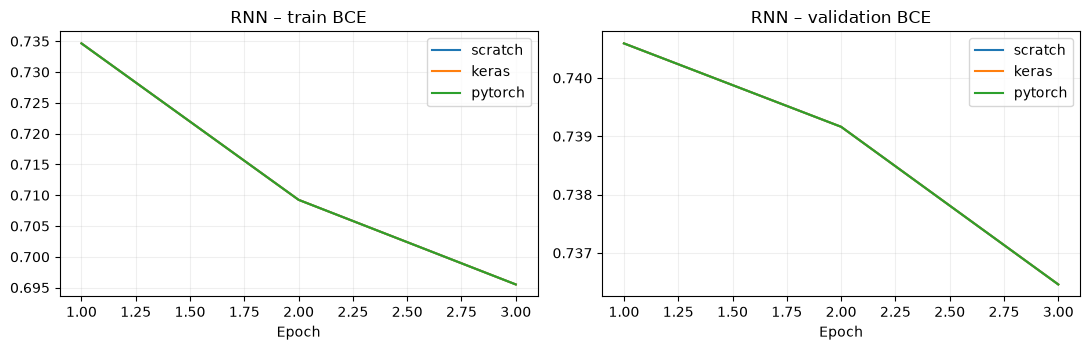

In [12]:
# Cell RNN-12
fig, axes = plt.subplots(1,2,figsize=(11,3.6))
for fw, history in curves.items():
    epochs = [r['epoch'] for r in history]
    axes[0].plot(epochs,[r['train_loss'] for r in history],label=fw)
    axes[1].plot(epochs,[r['val_loss'] for r in history],label=fw)
axes[0].set_title(KIND.upper()+' – train BCE')
axes[1].set_title(KIND.upper()+' – validation BCE')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT/(KIND+'_learning.png'),dpi=180)
plt.show()

## 3. Câu hỏi bảo vệ

    1. Hãy đọc biểu thức hợp hàm từ phải sang trái và chỉ shape tương ứng.
    2. Những lớp nào có tham số? Vì sao 20 thời điểm không thành 20 lớp?
    3. Vì sao phải align_weights trước khi so sánh?
    4. Gradient truyền qua từng hàm thế nào? Tại sao cần clipping?
    5. Loss giảm có bảo đảm AUC test tăng hay có lợi nhuận sau phí không?

    Kết quả trên tập con có thể dao động; phải báo cáo cả ba framework và
    giới hạn mẫu, không chọn riêng kết quả đẹp. Notebook không gửi lệnh giao dịch.